In [1]:
#Task 1: Load an imbalanced credit card fraud dataset and train logistic regression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, log_loss, accuracy_score

df = pd.read_csv("creditcard.csv")
print("Class counts (0 = normal, 1 = fraud):")
print(df["Class"].value_counts())

X = df.drop(columns="Class")
y = df["Class"]
xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(xtr, ytr)
probs = lr.predict_proba(xte)[:, 1]
print("\nTest accuracy:", round(lr.score(xte, yte), 3))

Class counts (0 = normal, 1 = fraud):
Class
0    4522
1     478
Name: count, dtype: int64

Test accuracy: 0.969


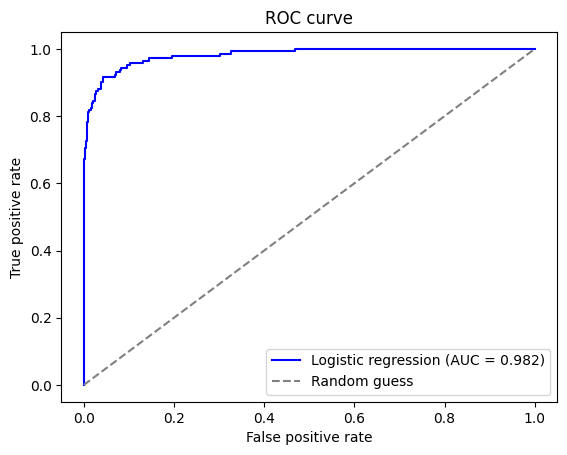

AUC: 0.982


In [2]:
#Task 2: ROC curve with AUC score
fpr, tpr, th = roc_curve(yte, probs)
auc = roc_auc_score(yte, probs)

plt.plot(fpr, tpr, color="blue", label="Logistic regression (AUC = " + str(round(auc, 3)) + ")")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

print("AUC:", round(auc, 3))

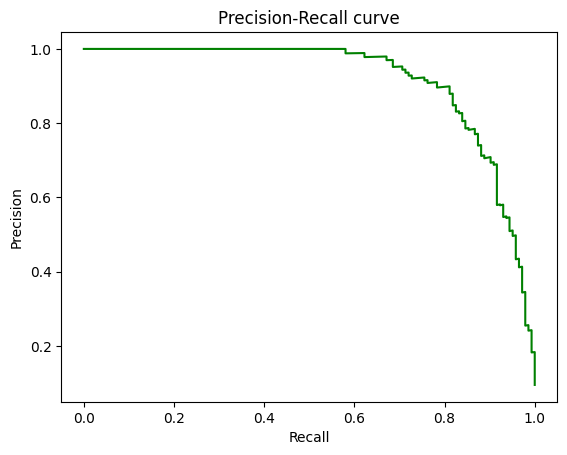

In [3]:
#Task 3: Precision-Recall curve
prec, rec, th = precision_recall_curve(yte, probs)

plt.plot(rec, prec, color="green")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve")
plt.show()

# This curve is useful for imbalanced data because it ignores the huge number of true negatives and only shows how well the rare positive class is found.

In [4]:
#Task 4: Log loss on the test set
ll = log_loss(yte, probs)
print("Log loss:", round(ll, 4))

Log loss: 0.083


In [5]:
#Task 5: Make the test set more imbalanced (2% fraud) and compare the metrics
rate = 0.02    # share of fraud in the new test set

neg_idx = yte[yte == 0].index
pos_idx = yte[yte == 1].index
n_pos = min(int(rate * len(neg_idx) / (1 - rate)), len(pos_idx))
keep = list(neg_idx) + list(np.random.default_rng(0).choice(pos_idx, n_pos, replace=False))

x2 = xte.loc[keep]
y2 = yte.loc[keep]
p2 = lr.predict_proba(x2)[:, 1]

print("Fraud share in old test set:", round(yte.mean(), 3), " new test set:", round(y2.mean(), 3))
print("Old test set -> accuracy:", round(lr.score(xte, yte), 3), "AUC:", round(auc, 3), "log loss:", round(ll, 4))
print("New test set -> accuracy:", round(lr.score(x2, y2), 3), "AUC:", round(roc_auc_score(y2, p2), 3), "log loss:", round(log_loss(y2, p2), 4))

# Even a model that says "not fraud" for everything would get an accuracy of 0.98 on the new test set.
# Accuracy is the most misleading metric. It went up (0.969 to 0.983) only because there are fewer frauds now, not because the model got better.
# AUC does not depend on how many positives there are, so it stays high (the small change comes from having fewer fraud samples), and log loss also drops because the hard fraud cases are fewer.

Fraud share in old test set: 0.095  new test set: 0.02
Old test set -> accuracy: 0.969 AUC: 0.982 log loss: 0.083
New test set -> accuracy: 0.983 AUC: 0.991 log loss: 0.0414
